# EDA of Economic and Market Features: EUR → INR

Training: **2020–2023** · Validation: **2024** · Test: **2025 onward**

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

path = Path("../data/processed/data_daily_base.csv")
df = pd.read_csv(path, parse_dates=["date"]).sort_values("date")
train_days = df[df["date"] < "2024-01-01"]
tr = train_days.dropna(subset=["eur_inr"]).copy()
tr["fx_1d"] = tr["eur_inr"].pct_change(fill_method=None) * 100
tr["fx_5d"] = (tr["eur_inr"].shift(-4) / tr["eur_inr"].shift(1) - 1) * 100
print("Training calendar days:", len(train_days))
print("ECB fixing days:", len(tr))
print("Training range:", tr["date"].min().date(), "to", tr["date"].max().date())


Training calendar days: 1461
ECB fixing days: 1027
Training range: 2020-01-02 to 2023-12-29


## 1. What is the data quality and how does EUR/INR behave?

In [ ]:
print("Shape:", df.shape)
print("Duplicate dates:", df["date"].duplicated().sum())
display(tr[["eur_inr", "fx_1d", "fx_5d"]].describe().round(3))
print("Calendar days without EUR/INR fixing:", train_days["eur_inr"].isna().sum())

Shape: (2500, 56)
Duplicate dates: 0


,eur_inr,fx_1d,fx_5d
count,1027.000,1026.000,1022.000
mean,86.011,0.015,0.073
std,3.436,0.470,1.076
min,77.234,-1.907,-3.131
25%,83.497,-0.263,-0.595
50%,86.938,0.011,-0.007
75%,88.645,0.273,0.644
max,92.449,2.361,5.425


Calendar days without EUR/INR fixing: 434


### Findings
- The original training sample has **1,461 calendar days** and **1,027 ECB fixing observations**.
- **434 calendar days** have no target fixing, mainly weekends and ECB holidays.

### EUR/INR distribution and changes

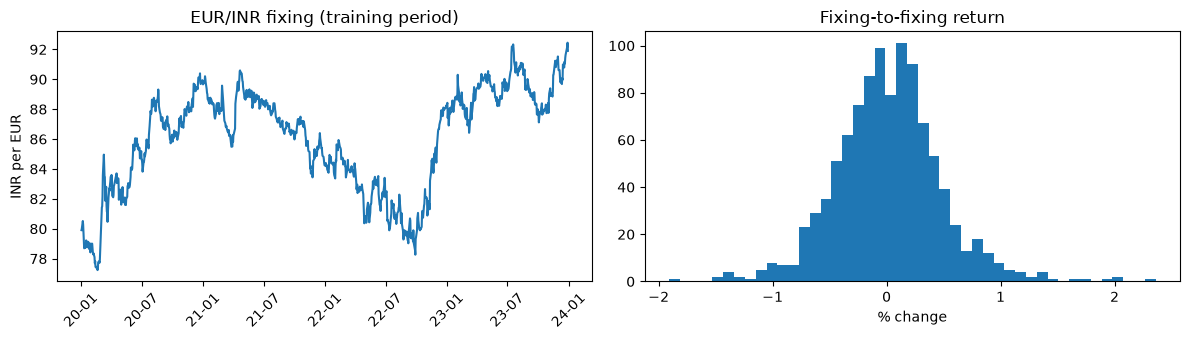

Median absolute daily change (%): 0.268
Median absolute weekly change (%): 0.631


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(tr["date"], tr["eur_inr"])
axes[0].set_title("EUR/INR fixing (training period)")
axes[0].set_ylabel("INR per EUR")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(tr["fx_1d"].dropna(), bins=45)
axes[1].set_title("Fixing-to-fixing return")
axes[1].set_xlabel("% change")
plt.tight_layout()
plt.show()
weekly = tr.set_index("date")["eur_inr"].resample("W-FRI").last().pct_change() * 100
print("Median absolute daily change (%):", round(tr["fx_1d"].abs().median(), 3))
print("Median absolute weekly change (%):", round(weekly.abs().median(), 3))

### Findings
- The median absolute **daily change ≈ 0.27%**, while median absolute **weekly change ≈ 0.63%**.
- Most fixing-to-fixing movements are modest, but occasional larger movements matter for transfer timing.

### Missingness and availability

In [ ]:
missing = pd.DataFrame({
    "Missing (all dates)": df.isna().sum(),
    "Percent (all dates)": (df.isna().mean() * 100).round(1),
    "Missing (train fixings)": tr[df.columns].isna().sum()
})
display(missing[missing["Missing (all dates)"] > 0]
        .sort_values("Percent (all dates)", ascending=False))

,Missing (all dates),Percent (all dates),Missing (train fixings)
eur_inr,750,30.0,0
fpi_equity_day,7,0.3,0
fpi_debt_day,7,0.3,0
fpi_total_day,7,0.3,0
eur_usd_usd_per_eur,2,0.1,1
usd_inr_inr_per_usd,2,0.1,1
brent_usd_per_barrel,2,0.1,1
us_10y_treasury_yield_pct,2,0.1,1
broad_usd_index_2006_100,2,0.1,1


### Findings
- Missing EUR/INR on non-fixing days is expected.
- Inspect feature gaps separately from the target calendar, and verify that forward-filled macroeconomic values were available at the time.

### Calendar patterns

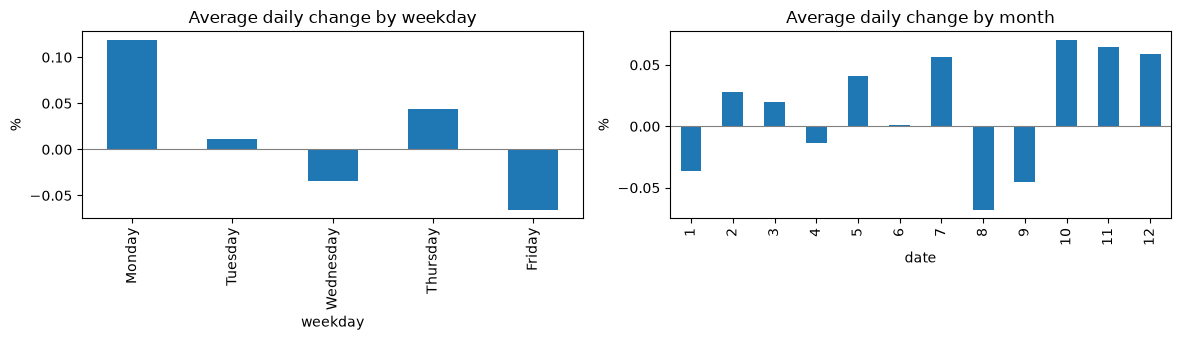

In [ ]:
tr["weekday"] = tr["date"].dt.day_name()
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
by_weekday = tr.groupby("weekday")["fx_1d"].mean().reindex(weekdays)
by_month = tr.groupby(tr["date"].dt.month)["fx_1d"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
by_weekday.plot.bar(ax=axes[0], title="Average daily change by weekday")
by_month.plot.bar(ax=axes[1], title="Average daily change by month")
for ax in axes:
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel("%")
plt.tight_layout(); plt.show()

Which weekday was highest within a full week?
This counts *historical* best days; it does **not** recommend a day to transfer.

In [ ]:
week = tr[["date", "eur_inr", "weekday"]].copy()
week["week"] = week["date"].dt.to_period("W-SUN")
full_weeks = week.groupby("week").filter(lambda group: len(group) == 5)
if len(full_weeks):
    best_rows = full_weeks.loc[full_weeks.groupby("week")["eur_inr"].idxmax()]
    display(best_rows["weekday"].value_counts().reindex(weekdays, fill_value=0)
            .rename("Weeks with highest EUR/INR").to_frame())

,Weeks with highest EUR/INR
weekday,
Monday,54
Tuesday,35
Wednesday,21
Thursday,35
Friday,49


## 2. How does EUR/USD × USD/INR relate to the target?

The currency cross-rate is an accounting relationship. Here the **previously available** quotes are compared with both the prior and the current EUR/INR fixing to illustrate alignment and potential leakage.

,Comparison,MAE (INR/EUR),Correlation
0,Cross vs previous fixing,0.0011,1.0000
1,Cross vs current fixing,0.3011,0.9933


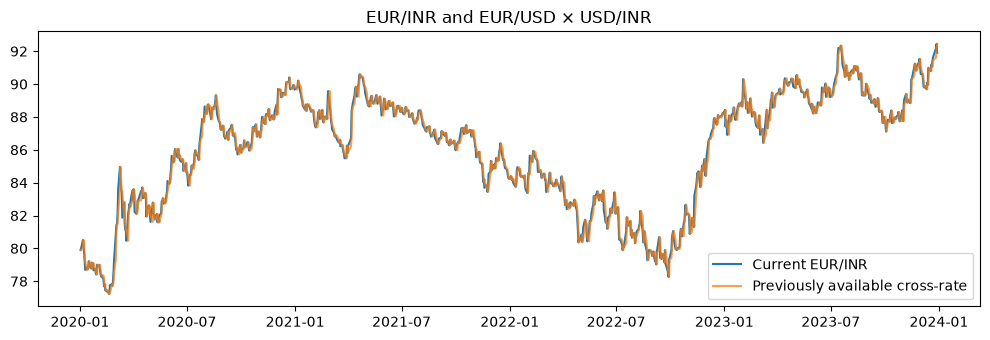

In [ ]:
cross = tr["eur_usd_usd_per_eur"] * tr["usd_inr_inr_per_usd"]
comparison = pd.DataFrame({
    "Comparison": ["Cross vs previous fixing", "Cross vs current fixing"],
    "MAE (INR/EUR)": [(cross - tr["eur_inr"].shift(1)).abs().mean(),
                      (cross - tr["eur_inr"]).abs().mean()],
    "Correlation": [cross.corr(tr["eur_inr"].shift(1)),
                    cross.corr(tr["eur_inr"])]
})
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tr["date"], tr["eur_inr"], label="Current EUR/INR")
ax.plot(tr["date"], cross, label="Previously available cross-rate", alpha=0.75)
ax.set_title("EUR/INR and EUR/USD × USD/INR"); ax.legend()
plt.tight_layout(); plt.show()

### Findings

-Lagged EUR/USD × USD/INR closely reconstructs the **previous** EUR/INR fixing (original analysis MAE ≈ ₹0.0011 per EUR).


## 3. Is Brent related to INR weakness?

In [ ]:
oil_change = tr["brent_usd_per_barrel"].pct_change() * 100
print("Average daily FX after oil rose:", round(tr.loc[oil_change > 0, "fx_1d"].mean(), 3), "%")
print("Average daily FX after oil fell:", round(tr.loc[oil_change < 0, "fx_1d"].mean(), 3), "%")
print("Oil / daily FX Spearman correlation:", round(oil_change.corr(tr["fx_1d"], method="spearman"), 3))

Average daily FX after oil rose: 0.06 %
Average daily FX after oil fell: -0.041 %
Oil / daily FX Spearman correlation: 0.1


### Findings

- The daily Pearson association between **Brent changes** and EUR/INR change was weak (≈ **+0.016**).
- The directional comparison and Spearman correlation provide descriptive context.

## 4. Do interest-rate differences matter?

In [ ]:
rate_gap = tr["rbi_repo_rate_pct"] - tr["ecb_deposit_rate_pct"]
print("Interest-rate gap | level corr:", round(rate_gap.corr(tr["fx_1d"]), 3),
      "| change corr:", round(rate_gap.diff().corr(tr["fx_1d"]), 3))
print("Policy-gap updates:", int(rate_gap.diff().fillna(0).ne(0).sum()))

Interest-rate gap | level corr: 0.002 | change corr: 0.031
Policy-gap updates: 17


### Findings

- The daily relationship for **changes in the policy-rate gap** was weak (≈ **+0.031**).

## 5. Do FPI outflows and reserve decreases precede INR weakness?

In [ ]:
fpi_days = train_days[["date", "fpi_total_day"]].sort_values("date")
fix_dates = tr[["date"]].rename(columns={"date": "fix_date"})
fpi_assigned = pd.merge_asof(fpi_days, fix_dates,
                             left_on="date", right_on="fix_date", direction="forward")
fpi_sum = fpi_assigned.groupby("fix_date")["fpi_total_day"].sum(min_count=1)
tr["fpi_interval"] = tr["date"].map(fpi_sum)
tr["fpi_group"] = np.select([tr["fpi_interval"] < 0, tr["fpi_interval"] > 0],
                             ["Outflow", "Inflow"], default="Zero / missing")
display(tr.groupby("fpi_group")[["fx_1d", "fx_5d"]].agg(["count", "mean"]).round(3))
print("FPI flow correlation with daily FX:", round(tr["fpi_interval"].corr(tr["fx_1d"]), 3))
tr["reserve_change"] = tr["total_usd_mn"].diff()
reserve_updates = tr[tr["reserve_change"].notna() & (tr["reserve_change"] != 0)].copy()
reserve_updates["direction"] = np.where(reserve_updates["reserve_change"] < 0,
                                         "Decrease", "Increase")
print("Reserve report transitions:", len(reserve_updates))
display(reserve_updates.groupby("direction")[["fx_1d", "fx_5d"]].mean().round(3))

fx_1d        fx_5d       
               count   mean count   mean
fpi_group                               
Inflow           514  0.002   511  0.037
Outflow          450  0.045   449  0.106
Zero / missing    62 -0.098    62  0.133

FPI flow correlation with daily FX: -0.004
Reserve report transitions: 208


,fx_1d,fx_5d
direction,,
Decrease,0.089,0.024
Increase,0.152,0.141


### Findings

- **FPI outflow intervals** averaged **+0.0451%** daily EUR/INR change versus **+0.0017%** during inflows, but the overall correlation was near zero.
- There are **208 reserve-report transitions**, including **94 decreases**. The effects were weak and inconsistent.


## 6. What happens when VIX is elevated?

In [ ]:
vix_cutoff = tr["vix"].quantile(0.90)
tr["high_vix"] = tr["vix"] >= vix_cutoff
display(tr.groupby("high_vix")[["fx_1d", "fx_5d"]].agg(["count", "mean"]).round(3))
print("High-VIX cutoff (training P90):", round(vix_cutoff, 2))

fx_1d        fx_5d       
         count   mean count   mean
high_vix                          
False      922  0.014   918  0.050
True       104  0.024   104  0.277

High-VIX cutoff (training P90): 31.37


### Findings

- The high-VIX observations had a higher mean **five-fixing EUR/INR change** (**+0.28%**) than other observations (**+0.05%**).
- A high VIX is a risk-condition indicator, not a causal or guaranteed prediction signal.

## 7. Is the India–euro inflation difference associated with FX?

In [ ]:
inflation_gap = tr["in_cpi_yoy"] - tr["ea_hicp_yoy"]
print("Inflation gap | level corr:", round(inflation_gap.corr(tr["fx_1d"]), 3),
      "| change corr:", round(inflation_gap.diff().corr(tr["fx_1d"]), 3))
print("Inflation-gap updates:", int(inflation_gap.diff().fillna(0).ne(0).sum()))

Inflation gap | level corr: -0.0 | change corr: -0.012
Inflation-gap updates: 91


### Findings

- Found little simple daily linear association between the inflation gap and EUR/INR returns.
- Inflation series update far less often than exchange rates. The underlying publication dates matter, and forward-filled values should not be confused with new releases.

## 8. What are the findings about growth, trade, credit risk, and redundancy?

### Macro indicators: growth, trade, sentiment and credit risk

In [ ]:
macro = ["ea_esi", "ea_gdp_yoy", "ea_unemployment", "in_gdp_yoy",
         "in_iip_yoy", "baa_spread", "ea_current_account_eur_bn",
         "ea_goods_balance_eur_bn", "india_exports_usd_bn", "india_imports_usd_bn"]
macro_summary = pd.DataFrame({
    "Distinct values": tr[macro].nunique(),
    "Missing": tr[macro].isna().sum(),
    "Daily FX corr (change)": tr[macro].diff().corrwith(tr["fx_1d"]).round(3)
})
display(macro_summary)

,Distinct values,Missing,Daily FX corr (change)
ea_esi,44,0,-0.091
ea_gdp_yoy,16,0,0.012
ea_unemployment,18,0,-0.052
in_gdp_yoy,16,0,-0.040
in_iip_yoy,41,0,0.015
baa_spread,161,0,0.067
ea_current_account_eur_bn,49,0,-0.028
ea_goods_balance_eur_bn,49,0,-0.013
india_exports_usd_bn,48,0,0.008
india_imports_usd_bn,48,0,-0.014


### Cross-feature comparison of changes

,Daily FX,Five-fixing FX
Brent change,0.015,0.049
RBI–ECB policy gap change,0.031,0.039
VIX change,-0.132,-0.073
Inflation gap change,-0.012,0.001
Baa spread change,0.067,0.068
Euro-area sentiment change,-0.091,0.004


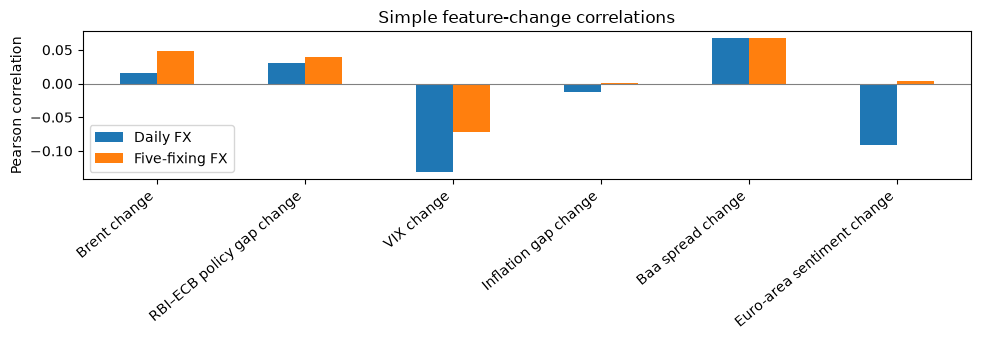

In [ ]:
features = {
    "Brent change": tr["brent_usd_per_barrel"].pct_change() * 100,
    "RBI–ECB policy gap change": (tr["rbi_repo_rate_pct"] - tr["ecb_deposit_rate_pct"]).diff(),
    "VIX change": tr["vix"].diff(),
    "Inflation gap change": (tr["in_cpi_yoy"] - tr["ea_hicp_yoy"]).diff(),
    "Baa spread change": tr["baa_spread"].diff(),
    "Euro-area sentiment change": tr["ea_esi"].diff(),
}
corrs = pd.DataFrame({
    name: {"Daily FX": values.corr(tr["fx_1d"]),
           "Five-fixing FX": values.corr(tr["fx_5d"])}
    for name, values in features.items()
}).T
display(corrs.round(3))
corrs.plot.bar(figsize=(10, 3.5), title="Simple feature-change correlations")
plt.axhline(0, color="grey", lw=0.8); plt.ylabel("Pearson correlation")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

### Redundancy between candidate predictors

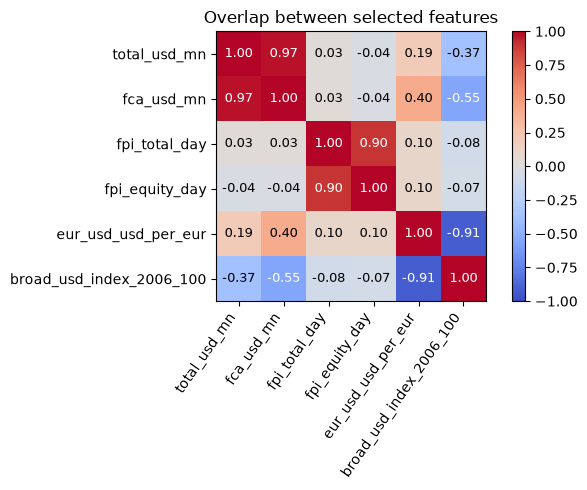

In [ ]:
selected = ["total_usd_mn", "fca_usd_mn", "fpi_total_day", "fpi_equity_day",
            "eur_usd_usd_per_eur", "broad_usd_index_2006_100"]

corr = tr[selected].corr()

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(selected)), selected, rotation=55, ha="right")
ax.set_yticks(range(len(selected)), selected)
for i in range(len(selected)):
    for j in range(len(selected)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.5 else "black", fontsize=9)

fig.colorbar(im, ax=ax)
ax.set_title("Overlap between selected features")
plt.tight_layout()
plt.show()

### Findings

- Growth, trade, sentiment and credit indicators typically change or are published much less often than FX fixings. Most simple daily associations in the original analysis were weak.
- **Total reserves** and **foreign-currency assets** highly correlated (r ≈ **0.97**).
- The daily correlation for **VIX changes** was somewhat larger in magnitude (≈ **−0.132**) but still does not imply causality.

## 9. Summary
| Feature | Decision | Why |
|---|---|---|
| EUR/USD × USD/INR | Use lagged values | Strong cross-rate relationship, but current values may cause data leakage |
| Brent oil price change | Add, test | Very weak daily correlation (≈ 0.016), but may capture oil-price shocks |
| RBI–ECB interest-rate gap | Test cautiously | Weak correlation (≈ 0.031); policy rates change infrequently |
| FPI flows | Check timing, then test | Outflows showed slightly higher EUR/INR changes than inflows |
| FX reserves | Lower priority | Weak relationship with FX movements; reserve data updates infrequently |
| VIX change / high-VIX flag | Add, test | High-VIX periods showed larger average five-fixing EUR/INR increases |
| India–euro inflation gap | Lower priority | Little relationship with daily FX changes |
| Growth, trade, sentiment and credit risk | Explore selectively | Most daily relationships were weak, and macroeconomic data updates slowly |
| Highly correlated features | Remove redundancy where useful | Total reserves and foreign-currency assets are strongly correlated (≈ 0.97) |

**Key messages**

1. **EUR/USD × USD/INR** closely reconstructs the previous EUR/INR fixing, but this does not guarantee future predictions.
2. **Brent oil and interest-rate differences** show weak daily relationships with EUR/INR, so their forecasting value needs testing.
3. **FPI outflows** were associated with slightly greater INR weakness (+0.045% versus +0.002% during inflows), but release timing must be checked.
4. **High VIX** was associated with larger five-fixing EUR/INR increases (+0.28% versus +0.05%), suggesting that global risk conditions may matter.
5. **Inflation, growth, and trade indicators** show limited daily relationships, while highly correlated features may provide overlapping information.
6. **Validate the selected features on 2024 data** without data leakage, and reserve 2025 onward for final testing.